## Part 1 - Project Setup.

### Import required libraries.

In [2]:
!pip install seaborn

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: C:\Python314\python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


### Load the dataset.

In [4]:
df = pd.read_csv("customer_feedback.csv")

print("Dataset loaded successfully!")
print(df.head())

Dataset loaded successfully!
   comment_id customer_type service_area  \
0           1           New      Support   
1           2           New        Sales   
2           3           New      Product   
3           4     Returning     Delivery   
4           5           New      Product   

                                        comment_text sentiment  \
0  My experience with the company was acceptable ...   neutral   
1  I am disappointed with the company because the...  negative   
2  The experience with this company was excellent...  positive   
3  I had a great experience and the company the s...  positive   
4  The experience with this company was excellent...  positive   

   satisfaction_score  resolution_needed  
0                   3                  0  
1                   2                  1  
2                   4                  0  
3                   4                  0  
4                   4                  0  


### Understand dataset structure.

In [5]:
# Total rows and columns
print("Dataset Shape:", df.shape)

# Column names
print("\nColumn Names:")
print(df.columns)

# Dataset information
print("\nDataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
print(df.describe())

Dataset Shape: (500, 7)

Column Names:
Index(['comment_id', 'customer_type', 'service_area', 'comment_text',
       'sentiment', 'satisfaction_score', 'resolution_needed'],
      dtype='str')

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   comment_id          500 non-null    int64
 1   customer_type       500 non-null    str  
 2   service_area        500 non-null    str  
 3   comment_text        500 non-null    str  
 4   sentiment           500 non-null    str  
 5   satisfaction_score  500 non-null    int64
 6   resolution_needed   500 non-null    int64
dtypes: int64(3), str(4)
memory usage: 27.5 KB

Statistical Summary:
       comment_id  satisfaction_score  resolution_needed
count  500.000000          500.000000         500.000000
mean   250.500000            3.332000           0.308000
std    144.481833            1

### Check basic dataset details.

In [6]:
# Check customer types
print(df["customer_type"].value_counts())

# Check service areas
print(df["service_area"].value_counts())

# Check sentiment
print(df["sentiment"].value_counts())

# Check satisfaction scores
print(df["satisfaction_score"].value_counts())

customer_type
New          259
Returning    241
Name: count, dtype: int64
service_area
Product     139
Support     129
Sales       116
Delivery    116
Name: count, dtype: int64
sentiment
positive    195
negative    154
neutral     151
Name: count, dtype: int64
satisfaction_score
4    166
5    110
2     88
3     70
1     66
Name: count, dtype: int64


## Part 2 – Data Cleaning.

### Check dataset information

In [7]:
print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   comment_id          500 non-null    int64
 1   customer_type       500 non-null    str  
 2   service_area        500 non-null    str  
 3   comment_text        500 non-null    str  
 4   sentiment           500 non-null    str  
 5   satisfaction_score  500 non-null    int64
 6   resolution_needed   500 non-null    int64
dtypes: int64(3), str(4)
memory usage: 27.5 KB


### Check missing values.

In [8]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
comment_id            0
customer_type         0
service_area          0
comment_text          0
sentiment             0
satisfaction_score    0
resolution_needed     0
dtype: int64


### Check duplicate records.

In [9]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


### Check unique values

In [10]:
print("Customer Types:")
print(df["customer_type"].unique())

print("\nService Areas:")
print(df["service_area"].unique())

print("\nSentiments:")
print(df["sentiment"].unique())

print("\nResolution Needed:")
print(df["resolution_needed"].unique())

Customer Types:
<StringArray>
['New', 'Returning']
Length: 2, dtype: str

Service Areas:
<StringArray>
['Support', 'Sales', 'Product', 'Delivery']
Length: 4, dtype: str

Sentiments:
<StringArray>
['neutral', 'negative', 'positive']
Length: 3, dtype: str

Resolution Needed:
[0 1]


### Check satisfaction score range.

In [11]:
print("Minimum Satisfaction Score:",
      df["satisfaction_score"].min())

print("Maximum Satisfaction Score:",
      df["satisfaction_score"].max())

Minimum Satisfaction Score: 1
Maximum Satisfaction Score: 5


### Clean the dataset.

In [12]:
# Remove duplicate records
df = df.drop_duplicates()

# Remove rows with missing values
df = df.dropna()

# Remove extra spaces from text columns
df["customer_type"] = df["customer_type"].str.strip()
df["service_area"] = df["service_area"].str.strip()
df["sentiment"] = df["sentiment"].str.strip().str.lower()
df["comment_text"] = df["comment_text"].str.strip()

print("Data Cleaning Completed!")

Data Cleaning Completed!


### Verify cleaned dataset.

In [13]:
print("Final Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Final Dataset Shape: (500, 7)

Missing Values:
comment_id            0
customer_type         0
service_area          0
comment_text          0
sentiment             0
satisfaction_score    0
resolution_needed     0
dtype: int64

Duplicate Rows:
0


## Part 3 – Exploratory Data Analysis (EDA).

### Customer type analysis.

In [14]:
customer_count = df["customer_type"].value_counts()

print("Customer Type Distribution:")
print(customer_count)

Customer Type Distribution:
customer_type
New          259
Returning    241
Name: count, dtype: int64


### Visualization:

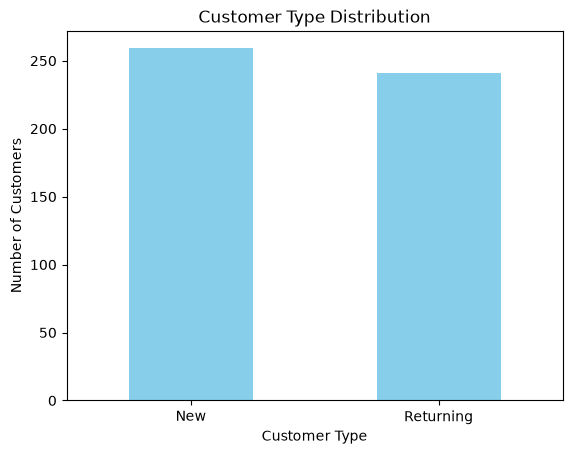

In [15]:
customer_count.plot(
    kind="bar",
    title="Customer Type Distribution",
    xlabel="Customer Type",
    ylabel="Number of Customers",
    color="skyblue"
)

plt.xticks(rotation=0)
plt.show()

### Service area analysis.

In [16]:
service_count = df["service_area"].value_counts()

print("Feedback by Service Area:")
print(service_count)

Feedback by Service Area:
service_area
Product     139
Support     129
Sales       116
Delivery    116
Name: count, dtype: int64


### Visualization:

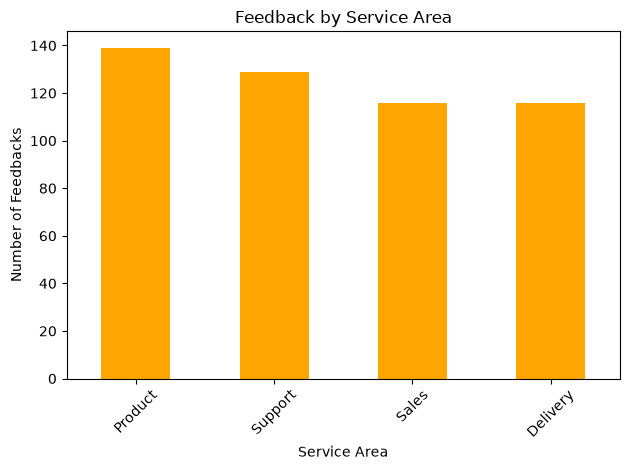

In [17]:
service_count.plot(
    kind="bar",
    title="Feedback by Service Area",
    xlabel="Service Area",
    ylabel="Number of Feedbacks",
    color="orange"
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Sentiment distribution analysis.

In [18]:
sentiment_count = df["sentiment"].value_counts()

print("Sentiment Distribution:")
print(sentiment_count)

Sentiment Distribution:
sentiment
positive    195
negative    154
neutral     151
Name: count, dtype: int64


### Visualization:

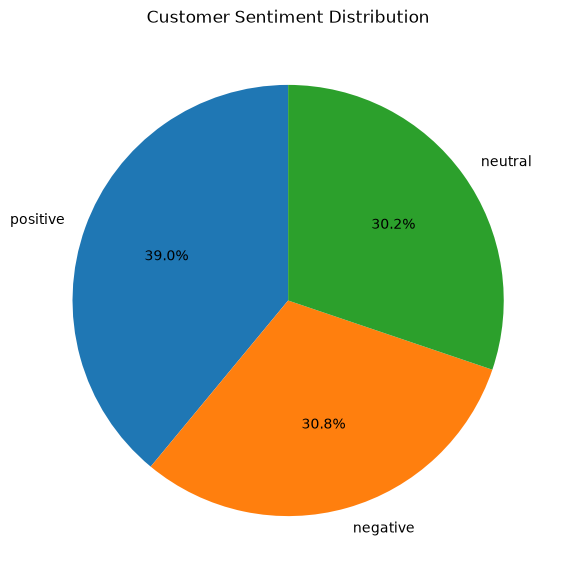

In [19]:
plt.figure(figsize=(7, 7))

sentiment_count.plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Customer Sentiment Distribution")
plt.ylabel("")
plt.show()

### Resolution required analysis.

In [20]:
resolution_count = df["resolution_needed"].value_counts()

print("Resolution Required:")
print(resolution_count)

Resolution Required:
resolution_needed
0    346
1    154
Name: count, dtype: int64


### Visualization:

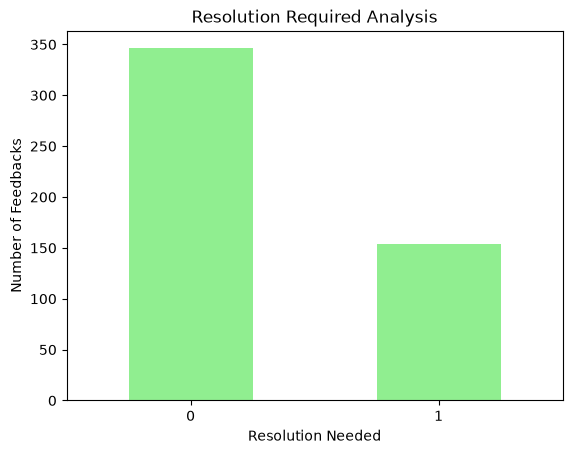

In [21]:
resolution_count.plot(
    kind="bar",
    color="lightgreen",
    title="Resolution Required Analysis",
    xlabel="Resolution Needed",
    ylabel="Number of Feedbacks"
)

plt.xticks(rotation=0)
plt.show()

### Satisfaction score analysis.

In [22]:
# Average Satisfaction Score

average_score = df["satisfaction_score"].mean()

print("Average Customer Satisfaction Score:",
      round(average_score, 2))

Average Customer Satisfaction Score: 3.33


In [23]:
# Satisfaction Score Distribution

score_count = df["satisfaction_score"].value_counts().sort_index()

print("Satisfaction Score Distribution:")
print(score_count)

Satisfaction Score Distribution:
satisfaction_score
1     66
2     88
3     70
4    166
5    110
Name: count, dtype: int64


### Visualization:

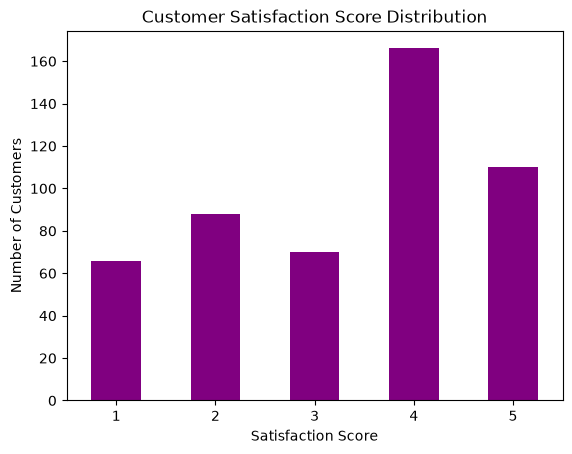

In [24]:
score_count.plot(
    kind="bar",
    color="purple",
    title="Customer Satisfaction Score Distribution",
    xlabel="Satisfaction Score",
    ylabel="Number of Customers"
)

plt.xticks(rotation=0)
plt.show()

### Overall EDA summary.

In [25]:
print("===== CUSTOMER FEEDBACK EDA SUMMARY =====")

print("\nTotal Feedback:", len(df))

print("\nCustomer Types:")
print(customer_count)

print("\nService Areas:")
print(service_count)

print("\nSentiment Distribution:")
print(sentiment_count)

print("\nResolution Required:")
print(resolution_count)

print("\nAverage Satisfaction Score:",
      round(average_score, 2))

===== CUSTOMER FEEDBACK EDA SUMMARY =====

Total Feedback: 500

Customer Types:
customer_type
New          259
Returning    241
Name: count, dtype: int64

Service Areas:
service_area
Product     139
Support     129
Sales       116
Delivery    116
Name: count, dtype: int64

Sentiment Distribution:
sentiment
positive    195
negative    154
neutral     151
Name: count, dtype: int64

Resolution Required:
resolution_needed
0    346
1    154
Name: count, dtype: int64

Average Satisfaction Score: 3.33


## Part 4 – Detailed Sentiment Analysis.

### Calculate sentiment percentages.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset again
df = pd.read_csv("customer_feedback.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

Dataset loaded successfully!
Dataset Shape: (500, 7)


In [3]:
# Sentiment Percentage Analysis

sentiment_percentage = (
    df["sentiment"].value_counts(normalize=True) * 100
)

print("Customer Sentiment Percentage:")

print(sentiment_percentage.round(2))

Customer Sentiment Percentage:
sentiment
positive    39.0
negative    30.8
neutral     30.2
Name: proportion, dtype: float64


### Analyze positive customer feedback.

In [4]:
# Filter Positive Feedback

positive_feedback = df[
    df["sentiment"] == "positive"
]

print("Total Positive Feedback:",
      len(positive_feedback))

print("\nPositive Customer Comments:")

print(
    positive_feedback["comment_text"].head(10)
)

Total Positive Feedback: 195

Positive Customer Comments:
2     The experience with this company was excellent...
3     I had a great experience and the company the s...
4     The experience with this company was excellent...
5     I had a great experience and the company custo...
9     The experience with this company was excellent...
10    The company did a great job and the product qu...
11    I am very satisfied with the service provided ...
12    I had a great experience and the company the r...
13    The experience with this company was excellent...
14    The experience with this company was excellent...
Name: comment_text, dtype: str


### Analyze negative customer feedback.

In [5]:
# Filter Negative Feedback

negative_feedback = df[
    df["sentiment"] == "negative"
]

print("Total Negative Feedback:",
      len(negative_feedback))

print("\nNegative Customer Comments:")

print(
    negative_feedback["comment_text"].head(10)
)

Total Negative Feedback: 154

Negative Customer Comments:
1     I am disappointed with the company because the...
7     I am disappointed with the company because the...
8     I would not recommend this company because cus...
15    The service did not meet my expectations and t...
19    The service did not meet my expectations and t...
22    The service did not meet my expectations and t...
24    I had a bad experience since the service had s...
28    I would not recommend this company because the...
30    I am disappointed with the company because the...
31    I am disappointed with the company because the...
Name: comment_text, dtype: str


### Identify common customer complaints.

In [7]:
from collections import Counter
import re

# Combine all negative comments
negative_text = " ".join(
    negative_feedback["comment_text"].astype(str)
)

# Convert to lowercase
negative_text = negative_text.lower()

# Extract words
words = re.findall(r'\b[a-z]+\b', negative_text)

# Remove common words
stop_words = {
    "the", "and", "was", "with", "because",
    "this", "that", "for", "not", "very",
    "company", "would", "i", "am", "a",
    "to", "my", "is", "it", "of"
}

filtered_words = [
    word for word in words
    if word not in stop_words
]

# Count word frequency
word_frequency = Counter(filtered_words)

print("Top 10 Common Complaint Words:")

print(word_frequency.most_common(10))

Top 10 Common Complaint Words:
[('had', 69), ('service', 68), ('bad', 40), ('experience', 40), ('since', 40), ('did', 39), ('meet', 39), ('expectations', 39), ('recommend', 38), ('disappointed', 37)]


### Analyze positive feedback keywords.

In [8]:
# Combine positive comments

positive_text = " ".join(
    positive_feedback["comment_text"].astype(str)
)

positive_text = positive_text.lower()

# Extract words
positive_words = re.findall(
    r'\b[a-z]+\b',
    positive_text
)

# Remove common words
positive_filtered = [
    word for word in positive_words
    if word not in stop_words
]

# Count frequency
positive_frequency = Counter(positive_filtered)

print("Top 10 Positive Feedback Words:")

print(positive_frequency.most_common(10))

Top 10 Positive Feedback Words:
[('excellent', 109), ('experience', 105), ('great', 96), ('time', 66), ('product', 53), ('quality', 53), ('had', 49), ('did', 47), ('job', 47), ('satisfied', 43)]


### Sentiment analysis by service area.

In [9]:
# Sentiment by Service Area

service_sentiment = pd.crosstab(
    df["service_area"],
    df["sentiment"]
)

print("Sentiment by Service Area:")

print(service_sentiment)

Sentiment by Service Area:
sentiment     negative  neutral  positive
service_area                             
Delivery            43       36        37
Product             29       48        62
Sales               42       28        46
Support             40       39        50


### Visualization:

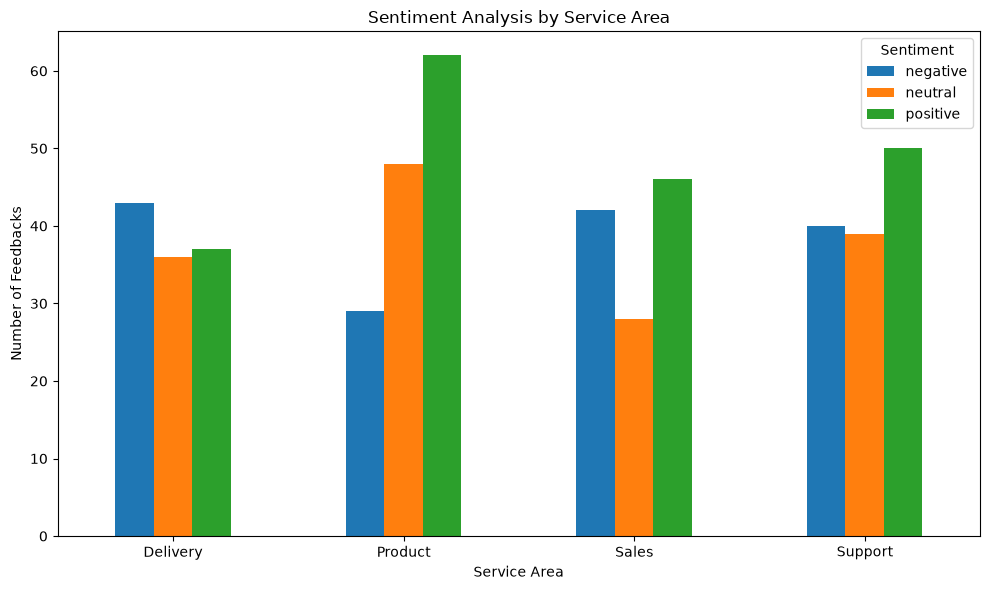

In [10]:
service_sentiment.plot(
    kind="bar",
    figsize=(10, 6),
    title="Sentiment Analysis by Service Area"
)

plt.xlabel("Service Area")
plt.ylabel("Number of Feedbacks")

plt.xticks(rotation=0)

plt.legend(title="Sentiment")

plt.tight_layout()

plt.show()

### Identify the department with the highest negative feedback.

In [11]:
# Find service area with maximum negative feedback

highest_negative_area = (
    service_sentiment["negative"].idxmax()
)

highest_negative_count = (
    service_sentiment["negative"].max()
)

print("Service Area with Highest Negative Feedback:",
      highest_negative_area)

print("Number of Negative Feedbacks:",
      highest_negative_count)

Service Area with Highest Negative Feedback: Delivery
Number of Negative Feedbacks: 43


## Part 5 – Customer Satisfaction Analysis.

### Calculate overall satisfaction score.

In [12]:
# Overall Customer Satisfaction

average_satisfaction = df["satisfaction_score"].mean()

print("Average Customer Satisfaction:",
      round(average_satisfaction, 2))

print("Maximum Satisfaction:",
      df["satisfaction_score"].max())

print("Minimum Satisfaction:",
      df["satisfaction_score"].min())

Average Customer Satisfaction: 3.33
Maximum Satisfaction: 5
Minimum Satisfaction: 1


### Analyze satisfaction by customer type.

In [13]:
# Satisfaction by Customer Type

customer_satisfaction = df.groupby(
    "customer_type"
)["satisfaction_score"].mean()

print("Customer Type Satisfaction:")
print(customer_satisfaction.round(2))

Customer Type Satisfaction:
customer_type
New          3.38
Returning    3.28
Name: satisfaction_score, dtype: float64


### Visualization:

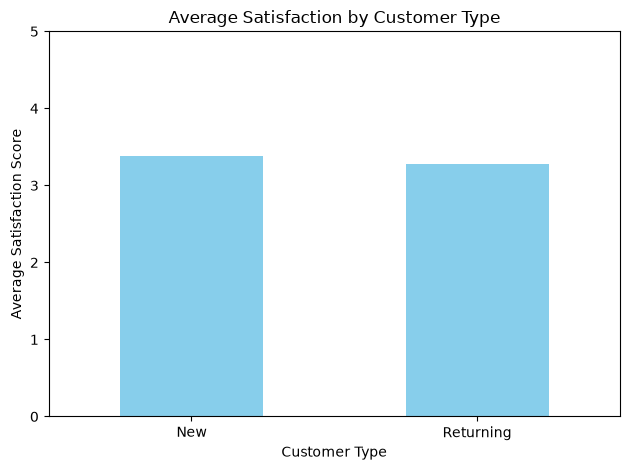

In [14]:
customer_satisfaction.plot(
    kind="bar",
    color="skyblue",
    title="Average Satisfaction by Customer Type",
    xlabel="Customer Type",
    ylabel="Average Satisfaction Score"
)

plt.ylim(0, 5)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Analyze satisfaction by service area.

In [15]:
# Satisfaction by Service Area

service_satisfaction = df.groupby(
    "service_area"
)["satisfaction_score"].mean()

print("Service Area Satisfaction:")
print(service_satisfaction.sort_values(ascending=False).round(2))

Service Area Satisfaction:
service_area
Product     3.55
Support     3.37
Sales       3.28
Delivery    3.09
Name: satisfaction_score, dtype: float64


### Visualization:

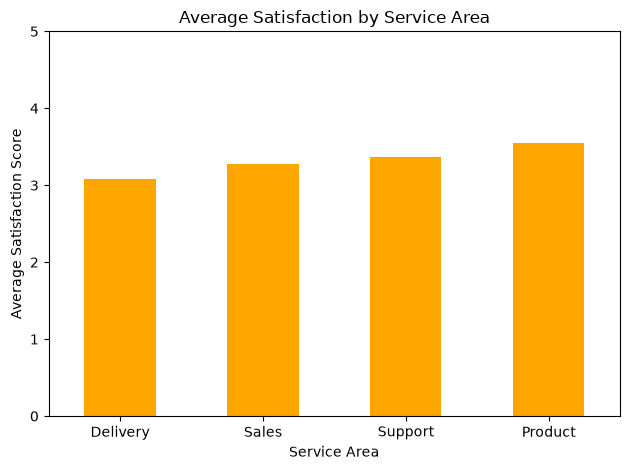

In [16]:
service_satisfaction.sort_values().plot(
    kind="bar",
    color="orange",
    title="Average Satisfaction by Service Area",
    xlabel="Service Area",
    ylabel="Average Satisfaction Score"
)

plt.ylim(0, 5)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Satisfaction score distribution.

In [17]:
# Satisfaction Score Distribution

score_distribution = df[
    "satisfaction_score"
].value_counts().sort_index()

print("Satisfaction Score Distribution:")
print(score_distribution)

Satisfaction Score Distribution:
satisfaction_score
1     66
2     88
3     70
4    166
5    110
Name: count, dtype: int64


### Visualization:

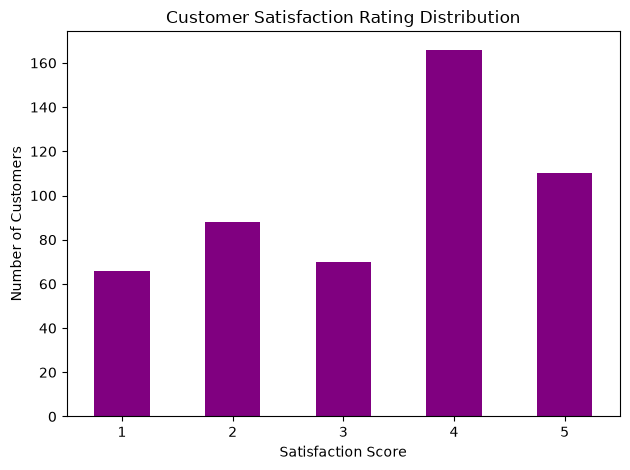

In [18]:
score_distribution.plot(
    kind="bar",
    color="purple",
    title="Customer Satisfaction Rating Distribution",
    xlabel="Satisfaction Score",
    ylabel="Number of Customers"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Satisfaction by sentiment.

In [19]:
# Satisfaction by Sentiment

sentiment_satisfaction = df.groupby(
    "sentiment"
)["satisfaction_score"].mean()

print("Satisfaction by Sentiment:")
print(sentiment_satisfaction.round(2))

Satisfaction by Sentiment:
sentiment
negative    1.57
neutral     3.54
positive    4.56
Name: satisfaction_score, dtype: float64


### Visualization:

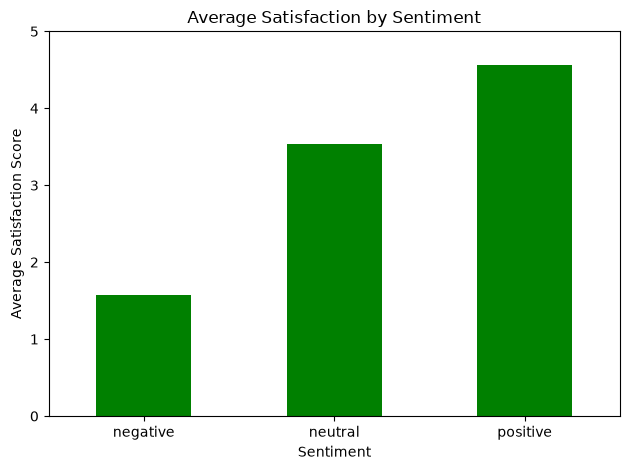

In [20]:
sentiment_satisfaction.plot(
    kind="bar",
    color="green",
    title="Average Satisfaction by Sentiment",
    xlabel="Sentiment",
    ylabel="Average Satisfaction Score"
)

plt.ylim(0, 5)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Final customer satisfaction summary.

In [21]:
print("===== CUSTOMER SATISFACTION REPORT =====")

print("\nOverall Satisfaction:",
      round(average_satisfaction, 2))

print("\nCustomer Type Satisfaction:")
print(customer_satisfaction.round(2))

print("\nService Area Satisfaction:")
print(service_satisfaction.round(2))

print("\nSatisfaction Distribution:")
print(score_distribution)

print("\nSentiment Satisfaction:")
print(sentiment_satisfaction.round(2))

print("\nHighest Satisfaction Service:",
      service_satisfaction.idxmax())

print("Lowest Satisfaction Service:",
      service_satisfaction.idxmin())

===== CUSTOMER SATISFACTION REPORT =====

Overall Satisfaction: 3.33

Customer Type Satisfaction:
customer_type
New          3.38
Returning    3.28
Name: satisfaction_score, dtype: float64

Service Area Satisfaction:
service_area
Delivery    3.09
Product     3.55
Sales       3.28
Support     3.37
Name: satisfaction_score, dtype: float64

Satisfaction Distribution:
satisfaction_score
1     66
2     88
3     70
4    166
5    110
Name: count, dtype: int64

Sentiment Satisfaction:
sentiment
negative    1.57
neutral     3.54
positive    4.56
Name: satisfaction_score, dtype: float64

Highest Satisfaction Service: Product
Lowest Satisfaction Service: Delivery


## Part 6 – Data Visualization.

### Prepare visualization environment.

In [22]:
# Import visualization libraries

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set chart style
sns.set_theme(style="whitegrid")

print("Visualization environment ready!")

Visualization environment ready!


### Pie Chart: Customer Sentiment Distribution.

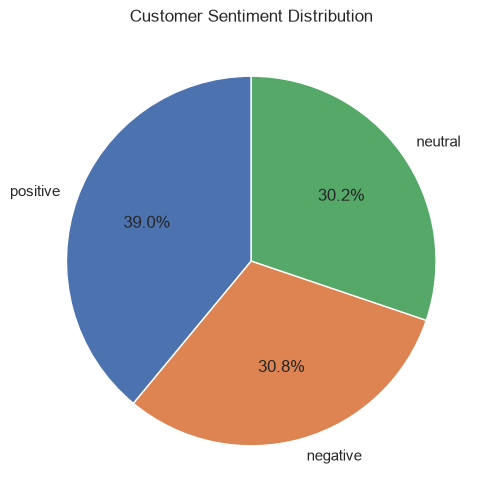

In [23]:
# Calculate sentiment counts

sentiment_count = df["sentiment"].value_counts()

# Create pie chart
plt.figure(figsize=(8, 6))

plt.pie(
    sentiment_count,
    labels=sentiment_count.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Customer Sentiment Distribution")

plt.show()

### Bar Chart: Customer Type Distribution.

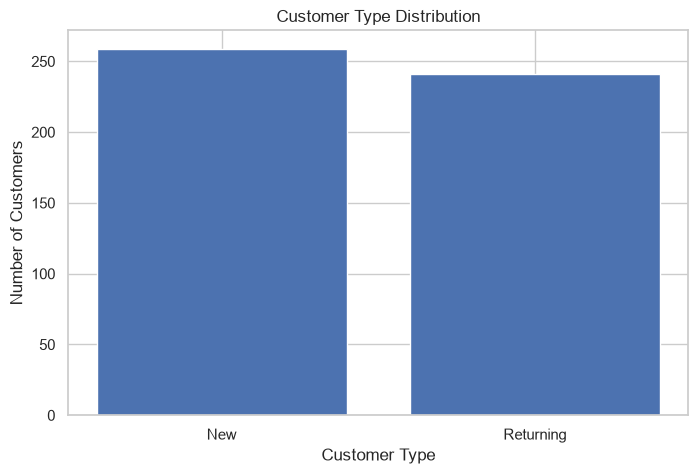

In [24]:
# Calculate customer counts

customer_count = df["customer_type"].value_counts()

# Create bar chart
plt.figure(figsize=(8, 5))

plt.bar(
    customer_count.index,
    customer_count.values
)

plt.title("Customer Type Distribution")
plt.xlabel("Customer Type")
plt.ylabel("Number of Customers")

plt.show()

### Bar Chart: Satisfaction by Service Area.

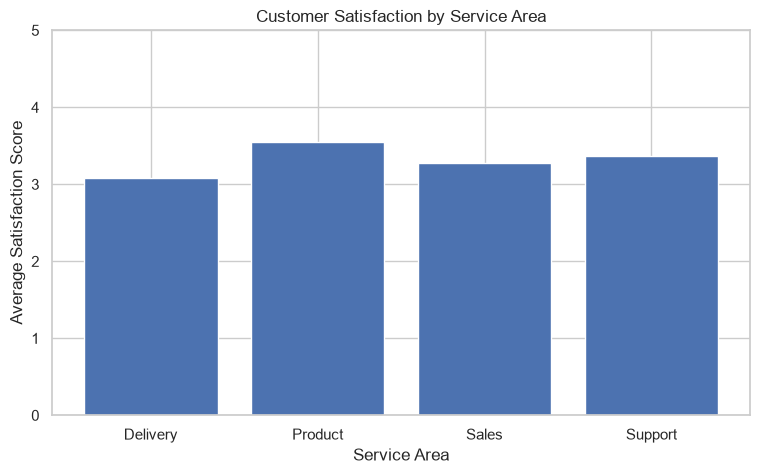

In [25]:
# Calculate average satisfaction by service area

service_satisfaction = df.groupby(
    "service_area"
)["satisfaction_score"].mean()

# Create bar chart
plt.figure(figsize=(9, 5))

plt.bar(
    service_satisfaction.index,
    service_satisfaction.values
)

plt.title("Customer Satisfaction by Service Area")
plt.xlabel("Service Area")
plt.ylabel("Average Satisfaction Score")

plt.ylim(0, 5)

plt.show()

### Histogram: Satisfaction Score Distribution.

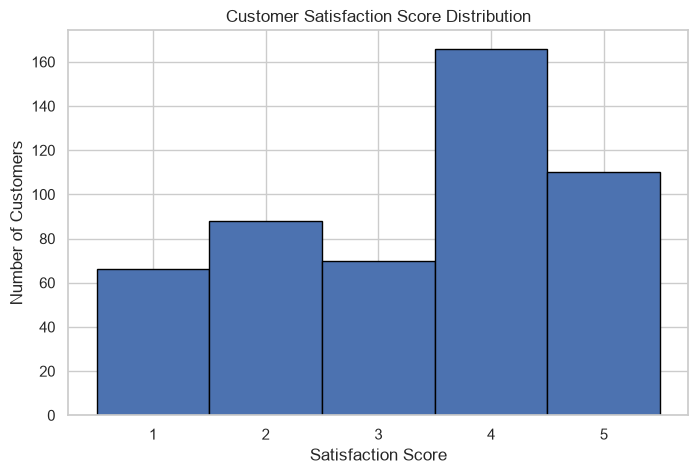

In [26]:
# Create histogram

plt.figure(figsize=(8, 5))

plt.hist(
    df["satisfaction_score"],
    bins=[0.5, 1.5, 2.5, 3.5, 4.5, 5.5],
    edgecolor="black"
)

plt.title("Customer Satisfaction Score Distribution")
plt.xlabel("Satisfaction Score")
plt.ylabel("Number of Customers")

plt.xticks([1, 2, 3, 4, 5])

plt.show()

### Stacked Bar Chart: Sentiment by Service Area.

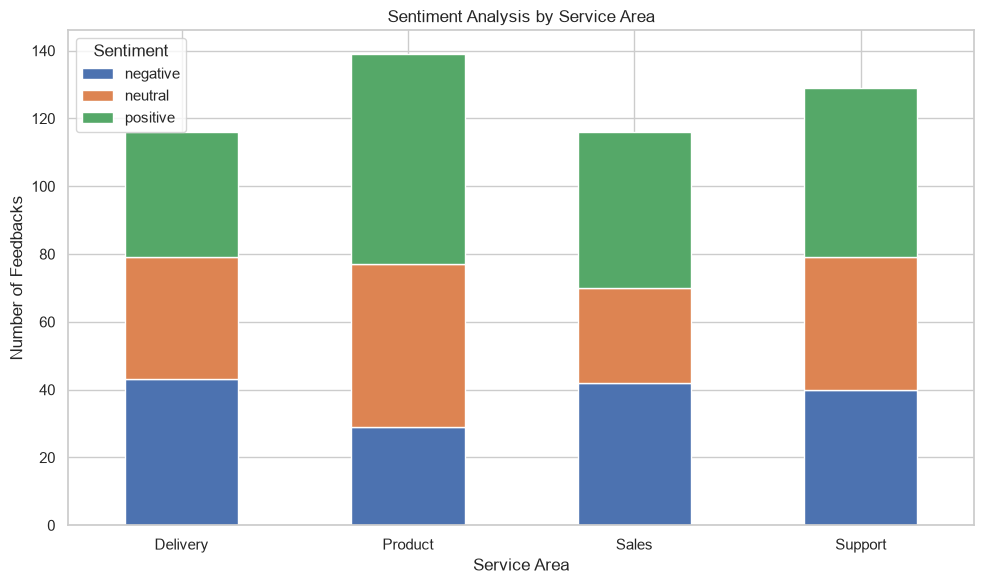

In [27]:
# Create sentiment comparison

service_sentiment = pd.crosstab(
    df["service_area"],
    df["sentiment"]
)

# Create stacked bar chart

service_sentiment.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Sentiment Analysis by Service Area")
plt.xlabel("Service Area")
plt.ylabel("Number of Feedbacks")

plt.xticks(rotation=0)

plt.legend(title="Sentiment")

plt.tight_layout()

plt.show()

In [28]:
plt.savefig(
    "chart_name.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

## Part 7 – Business Insights and Recommendations.

### Identify the major customer problems.

In [29]:
# Identify negative customer feedback

negative_feedback = df[
    df["sentiment"] == "negative"
]

print("Total Negative Feedback:",
      len(negative_feedback))

print("\nCustomer Complaints:")

print(
    negative_feedback["comment_text"].head(15)
)

Total Negative Feedback: 154

Customer Complaints:
1     I am disappointed with the company because the...
7     I am disappointed with the company because the...
8     I would not recommend this company because cus...
15    The service did not meet my expectations and t...
19    The service did not meet my expectations and t...
22    The service did not meet my expectations and t...
24    I had a bad experience since the service had s...
28    I would not recommend this company because the...
30    I am disappointed with the company because the...
31    I am disappointed with the company because the...
37    I am disappointed with the company because cus...
42    I am disappointed with the company because the...
45    I am disappointed with the company because the...
46    The service did not meet my expectations and c...
49    I had a bad experience since the product arriv...
Name: comment_text, dtype: str


### Identify the worst-performing service area.

In [30]:
# Average satisfaction by service area

service_satisfaction = df.groupby(
    "service_area"
)["satisfaction_score"].mean()

worst_service = service_satisfaction.idxmin()

worst_score = service_satisfaction.min()

print("Worst Performing Service Area:",
      worst_service)

print("Average Satisfaction Score:",
      round(worst_score, 2))

Worst Performing Service Area: Delivery
Average Satisfaction Score: 3.09


### Calculate negative feedback percentage.

In [31]:
# Calculate negative feedback percentage

total_feedback = len(df)

negative_count = len(
    df[df["sentiment"] == "negative"]
)

negative_percentage = (
    negative_count / total_feedback
) * 100

print("Total Feedback:", total_feedback)

print("Negative Feedback:", negative_count)

print("Negative Feedback Percentage:",
      round(negative_percentage, 2), "%")

Total Feedback: 500
Negative Feedback: 154
Negative Feedback Percentage: 30.8 %


### Analyze customer issues requiring resolution.

In [32]:
# Resolution Analysis

resolution_summary = df[
    "resolution_needed"
].value_counts()

print("Resolution Summary:")
print(resolution_summary)

print("\nTotal Cases Requiring Resolution:",
      df["resolution_needed"].sum())

Resolution Summary:
resolution_needed
0    346
1    154
Name: count, dtype: int64

Total Cases Requiring Resolution: 154


In [33]:
resolution_percentage = (
    df["resolution_needed"].sum() / len(df)
) * 100

print("Resolution Required Percentage:",
      round(resolution_percentage, 2), "%")

Resolution Required Percentage: 30.8 %


### Compare negative feedback across departments.

In [34]:
# Negative feedback by service area

negative_by_service = df[
    df["sentiment"] == "negative"
].groupby("service_area").size()

print("Negative Feedback by Service Area:")
print(negative_by_service.sort_values(
    ascending=False
))

Negative Feedback by Service Area:
service_area
Delivery    43
Sales       42
Support     40
Product     29
dtype: int64


### Calculate the percentage for each department:

In [35]:
# Percentage of negative feedback within each service area

negative_service_percentage = (
    df.assign(
        is_negative=df["sentiment"] == "negative"
    )
    .groupby("service_area")["is_negative"]
    .mean() * 100
)

print("\nNegative Feedback Percentage by Service Area:")

print(negative_service_percentage.round(2))


Negative Feedback Percentage by Service Area:
service_area
Delivery    37.07
Product     20.86
Sales       36.21
Support     31.01
Name: is_negative, dtype: float64


### Create a final business insights summary.

In [36]:
print("====================================")
print(" CUSTOMER FEEDBACK BUSINESS REPORT")
print("====================================")

print("\n1. Total Customer Feedback:", len(df))

print("\n2. Average Satisfaction:",
      round(df["satisfaction_score"].mean(), 2))

print("\n3. Negative Feedback:",
      negative_count)

print("\n4. Negative Feedback Percentage:",
      round(negative_percentage, 2), "%")

print("\n5. Worst Performing Service:",
      worst_service)

print("\n6. Lowest Satisfaction Score:",
      round(worst_score, 2))

print("\n7. Resolution Required Cases:",
      int(df["resolution_needed"].sum()))

print("\n8. Highest Negative Feedback Department:",
      negative_by_service.idxmax())

print("\n====================================")

 CUSTOMER FEEDBACK BUSINESS REPORT

1. Total Customer Feedback: 500

2. Average Satisfaction: 3.33

3. Negative Feedback: 154

4. Negative Feedback Percentage: 30.8 %

5. Worst Performing Service: Delivery

6. Lowest Satisfaction Score: 3.09

7. Resolution Required Cases: 154

8. Highest Negative Feedback Department: Delivery

